# Immune sub-clustering (3-layer pipeline)

This notebook continues from `04_cell_type_annotation.ipynb`: it subsets the `Immune` compartment (from `lv1_annotation`), re-clusters it at finer resolution, and annotates the resulting sub-clusters using the same three complementary layers of evidence.

1. **Canonical/known marker annotation** — score each sub-cluster against the lymphoid/myeloid-relevant curated marker sets.
2. **DEG-driven manual annotation** — pull top DEGs per sub-cluster, cross-check against literature/Protein Atlas, and record a manual label.
3. **Functional enrichment (GO/KEGG/Reactome)** — run over-representation analysis on sub-cluster DEGs to support/refine the label.

Outputs are written to `results/xenium_5k/annotation/subclustering/immune/`.

In [1]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import spatialdata as sd
import spatialdata_plot
import gseapy as gp

%load_ext autoreload
%autoreload 2

warnings.filterwarnings('ignore')

GROUP = 'Immune'
annot_dir = '../../results/xenium_5k/annotation/subclustering/immune'
os.makedirs(annot_dir, exist_ok=True)

/home/duydao/micromamba/envs/spatial_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load the lv1-annotated object saved at the end of notebook 04 and subset to this compartment
sdata = sd.read_zarr('../../data/spatialdata/xenium_prime_5k_lv1_annotated.zarr')
adata_full = sdata['table']
adata = adata_full[adata_full.obs['lv1_annotation'] == GROUP].copy()
print(f'{adata.n_obs} cells in the {GROUP} compartment (of {adata_full.n_obs} total)')

no parent found for <ome_zarr.reader.Label object at 0x7899ca7a8290>: None
no parent found for <ome_zarr.reader.Label object at 0x7899c8c620c0>: None


106536 cells in the Immune compartment (of 266179 total)


## Sub-clustering

Fresh HVG -> PCA -> neighbors -> Leiden on just this compartment's cells (mirrors `02_Xenium_5k_downstream_qc_filter_clustering_python.ipynb`'s parameters). Bump `sub_resolution` if sub-types still look merged.

In [3]:
sub_resolution = 0.6

sc.pp.highly_variable_genes(adata, flavor='seurat_v3', n_top_genes=2000)
sc.pp.pca(adata, n_comps=30)
sc.pp.neighbors(adata, metric='cosine')
sc.tl.leiden(adata, key_added='sub_leiden', flavor='igraph', n_iterations=-1, resolution=sub_resolution)
sc.tl.umap(adata)

adata.obs['sub_leiden'] = adata.obs['sub_leiden'].astype('category')
sub_clusters = adata.obs['sub_leiden'].cat.categories.tolist()
print(f'{len(sub_clusters)} sub-clusters, {adata.n_obs} cells')

17 sub-clusters, 106536 cells


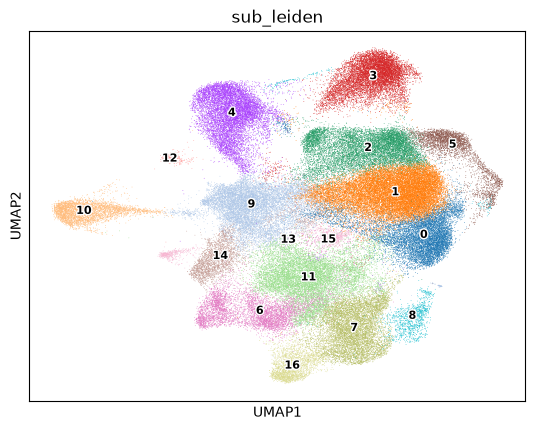

In [4]:
# fixed palette shared with the spatial cluster plot below

cluster_colors = dict(zip(sub_clusters, sc.pl.palettes.default_20 if len(sub_clusters) <= 20 else sc.pl.palettes.default_102))
sc.pl.umap(adata, color='sub_leiden', legend_loc='on data', legend_fontsize=8, legend_fontoutline=2)

adata.uns['sub_leiden_colors'] = [cluster_colors[c] for c in sub_clusters]

## Layer 1 — Canonical/known marker annotation

Reuses the curated marker dict from `04_cell_type_annotation.ipynb`, filtered down to the signatures relevant to this compartment (plus `Proliferating`, useful in every compartment).

In [5]:
canonical_markers_all = {
    'Epithelial_AT1': ['AGER', 'PDPN', 'CAV1'],
    'Epithelial_AT2': ['LAMP3', 'ABCA3', 'SLC34A2', 'TCIM', 'SFTPC', 'SFTPB', 'SFTPA1', 'NAPSA'],
    'Epithelial_Airway_Ciliated': ['FOXJ1', 'TPPP3', 'PIFO'],
    'Epithelial_Airway_Club_Secretory': ['SCGB1A1', 'SCGB3A1', 'MUC5B'],
    'Epithelial_Tumor_Malignant': ['EPCAM', 'KRT8', 'KRT18', 'KRT19'],
    'Epithelial_LUAD (Adenocarcinoma)': ['NAPSA', 'NKX2-1', 'SFTPC', 'SFTPB', 'MUC5AC', 'MUC5B', 'KRT7'],
    'Lymphoid_T_cell_CD4': ['CD3D', 'CD3E', 'CD2', 'TRAC', 'CD4'],
    'Lymphoid_T_cell_CD8': ['CD3D', 'CD3E', 'CD2', 'TRAC', 'CD8A', 'CD8B'],
    'Lymphoid_T_cell_CD8_exhausted': ['PDCD1', 'HAVCR2', 'LAG3', 'TIGIT', 'TOX', 'EOMES','ENTPD1','CXCL13'],
    'Lymphoid_NK_cell': ['NKG7', 'GNLY', 'KLRD1'],
    'Lymphoid_B_cell': ['MS4A1', 'CD79A', 'CD79B'],
    'Lymphoid_Plasma_cell': ['MZB1', 'JCHAIN', 'IGHG1'],
    'Myeloid_Macrophage_M1': ['CD68', 'CD86', 'CD80', 'IL1B', 'TNF', 'NOS2', 'IL6', 'IL12A'],
    'Myeloid_Macrophage_M2': ['CD68', 'CD163', 'MRC1', 'CCL18', 'MSR1', 'IL10', 'TGM2', 'TGFB1'],
    'Myeloid_Monocyte': ['CD14', 'CD74', 'LYZ', 'ITGAM'],
    'Myeloid_Neutrophil': ['FCGR3B', 'FMLP2', 'CEBPE', 'MPO', 'ELANE', 'AZU1', 'LILRA5', 'MXD1', 'CSF3R'],
    'Myeloid_Dendritic_cell': ['CD74', 'FCER1A', 'CST3', 'AIF1'],
    'Myeloid_Mast_cell': ['TPSAB1', 'TPSB2', 'CPA3', 'CMA1', 'KIT'],
    'Stromal_Fibroblast': ['COL1A1', 'COL1A2', 'DCN', 'PDGFRA'],
    'Stromal_Smooth_muscle/Pericyte': ['ACTA2', 'MYH11', 'PDGFRB'],
    'Vessels_EC': ['PECAM1', 'VWF', 'CLDN5'],
    'Proliferating': ['MKI67', 'TOP2A', 'PCNA', 'CDK1', 'UBE2C', 'BIRC5', 'CCNB1', 'CCNB2', 'MCM2', 'MCM5'],
}

# Keep only the marker sets relevant to this compartment (+ Proliferating)
group_prefixes = ('Lymphoid_', 'Myeloid_')
extra_keys = {'Proliferating'}
canonical_markers = {
    k: v for k, v in canonical_markers_all.items()
    if k.startswith(group_prefixes) or k in extra_keys
}

# Keep only genes present in the panel, and drop cell types left with no genes
canonical_markers = {
    cell_type: [g for g in genes if g in adata.var_names]
    for cell_type, genes in canonical_markers.items()
}
missing = {k: v for k, v in canonical_markers.items() if len(v) == 0}
if missing:
    print('Cell types with no marker genes found in panel (dropped):', list(missing.keys()))
canonical_markers = {k: v for k, v in canonical_markers.items() if len(v) > 0}
canonical_markers

{'Lymphoid_T_cell_CD4': ['CD3E', 'CD2', 'CD4'],
 'Lymphoid_T_cell_CD8': ['CD3E', 'CD2', 'CD8A', 'CD8B'],
 'Lymphoid_T_cell_CD8_exhausted': ['PDCD1',
  'HAVCR2',
  'LAG3',
  'TIGIT',
  'TOX',
  'EOMES',
  'ENTPD1',
  'CXCL13'],
 'Lymphoid_NK_cell': ['KLRD1'],
 'Lymphoid_B_cell': ['MS4A1', 'CD79A', 'CD79B'],
 'Lymphoid_Plasma_cell': ['MZB1'],
 'Myeloid_Macrophage_M1': ['CD68',
  'CD86',
  'CD80',
  'IL1B',
  'TNF',
  'NOS2',
  'IL6',
  'IL12A'],
 'Myeloid_Macrophage_M2': ['CD68',
  'CD163',
  'MRC1',
  'CCL18',
  'MSR1',
  'IL10',
  'TGM2',
  'TGFB1'],
 'Myeloid_Monocyte': ['CD14', 'ITGAM'],
 'Myeloid_Neutrophil': ['FCGR3B', 'MPO', 'ELANE', 'LILRA5', 'MXD1', 'CSF3R'],
 'Myeloid_Dendritic_cell': ['FCER1A'],
 'Myeloid_Mast_cell': ['CMA1', 'KIT'],
 'Proliferating': ['MKI67',
  'TOP2A',
  'PCNA',
  'CDK1',
  'UBE2C',
  'BIRC5',
  'CCNB1',
  'CCNB2',
  'MCM2',
  'MCM5']}

In [6]:
adata.obs.drop(columns=[c for c in adata.obs.columns if c.startswith('score_')], inplace=True, errors='ignore')
for cell_type, genes in canonical_markers.items():
    sc.tl.score_genes(adata, gene_list=genes, score_name=f'score_{cell_type}', layer='lognorm')

score_cols = [f'score_{ct}' for ct in canonical_markers]
cluster_scores = adata.obs.groupby('sub_leiden', observed=True)[score_cols].mean()
cluster_scores.columns = list(canonical_markers.keys())
cluster_scores

,Lymphoid_T_cell_CD4,Lymphoid_T_cell_CD8,Lymphoid_T_cell_CD8_exhausted,Lymphoid_NK_cell,Lymphoid_B_cell,Lymphoid_Plasma_cell,Myeloid_Macrophage_M1,Myeloid_Macrophage_M2,Myeloid_Monocyte,Myeloid_Neutrophil,Myeloid_Dendritic_cell,Myeloid_Mast_cell,Proliferating
sub_leiden,,,,,,,,,,,,,
0,0.185795,0.132213,0.060958,-0.011291,-0.024849,-0.124997,-0.016181,-0.031725,-0.075637,-0.015825,-0.007215,-0.021616,-0.000573
1,0.208870,0.160988,-0.011707,-0.007928,-0.030555,-0.127932,-0.018290,-0.036652,-0.087090,-0.014686,-0.006843,-0.020482,-0.005468
2,0.105162,0.274439,0.014086,0.083578,-0.029418,-0.121411,-0.016169,-0.034750,-0.066193,-0.012963,-0.006780,-0.020114,-0.006987
3,-0.149510,-0.067656,-0.004167,-0.011901,0.453824,-0.097838,-0.009997,-0.040025,-0.061892,-0.017517,-0.008422,-0.021663,0.002543
4,-0.153768,-0.089920,-0.016848,-0.009523,0.134847,0.924962,-0.014125,-0.033061,-0.071181,-0.015370,-0.009634,-0.020529,-0.007629
5,0.173337,0.418649,0.105431,0.032611,-0.054718,-0.150361,-0.022534,-0.048730,-0.094456,-0.020188,-0.009501,-0.025528,0.051353
6,-0.126228,-0.110091,-0.004813,-0.013011,-0.059079,-0.183288,0.036504,0.021677,0.122603,0.054175,0.047728,-0.023512,-0.004060
7,-0.116566,-0.148206,-0.001950,-0.013971,-0.073832,-0.203427,0.112106,0.270540,0.275274,0.022622,-0.008263,-0.024577,-0.005515
8,-0.154111,-0.122666,-0.006629,-0.014385,-0.048262,-0.136820,0.034361,0.065795,0.101526,0.001956,0.012858,-0.027139,0.121034


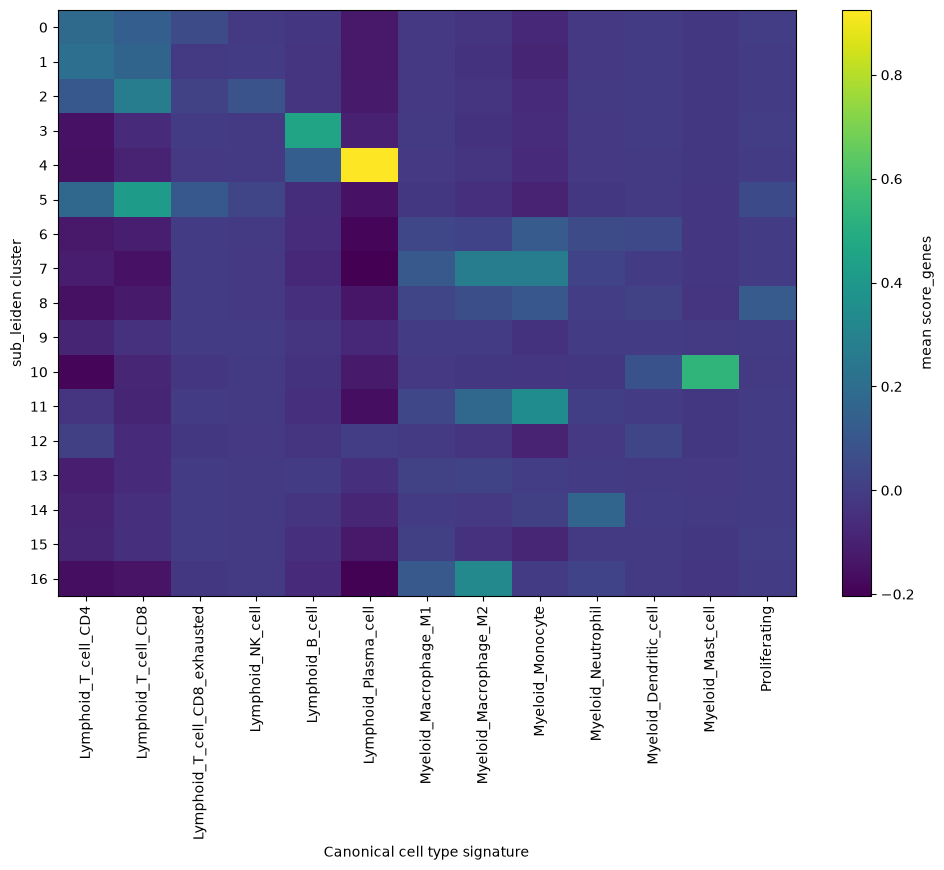

In [7]:
fig, ax = plt.subplots(figsize=(10, 0.4 * len(cluster_scores) + 2))
im = ax.imshow(cluster_scores.values, cmap='viridis', aspect='auto')
ax.set_xticks(range(len(cluster_scores.columns)))
ax.set_xticklabels(cluster_scores.columns, rotation=90)
ax.set_yticks(range(len(cluster_scores)))
ax.set_yticklabels(cluster_scores.index)
ax.set_xlabel('Canonical cell type signature')
ax.set_ylabel('sub_leiden cluster')
fig.colorbar(im, ax=ax, label='mean score_genes')
plt.tight_layout()

In [8]:
layer1_annotation = pd.DataFrame({
    'cluster': cluster_scores.index,
    'canonical_label': cluster_scores.idxmax(axis=1).values,
    'canonical_score': cluster_scores.max(axis=1).values,
}).reset_index(drop=True)
layer1_annotation

,cluster,canonical_label,canonical_score
0,0,Lymphoid_T_cell_CD4,0.185795
1,1,Lymphoid_T_cell_CD4,0.208870
2,2,Lymphoid_T_cell_CD8,0.274439
3,3,Lymphoid_B_cell,0.453824
4,4,Lymphoid_Plasma_cell,0.924962
5,5,Lymphoid_T_cell_CD8,0.418649
6,6,Myeloid_Monocyte,0.122603
7,7,Myeloid_Monocyte,0.275274
8,8,Proliferating,0.121034
9,9,Proliferating,-0.004102


In [9]:
def plot_subcluster_score(adata, sdata, cell_type_name, figsize=(12.8, 9.6)):
    """Plot a sub-cluster marker score spatially by projecting it onto the full sdata table (in-memory only)."""
    score_col = f'score_{cell_type_name}'
    if score_col not in adata.obs.columns:
        print(f"Score column '{score_col}' not found in adata.obs")
        print('Available score columns:', [c for c in adata.obs.columns if c.startswith('score_')])
        return

    plot_col = re.sub(r'[^A-Za-z0-9_.-]', '_', score_col)
    full_table = sdata.tables['table']
    full_table.obs[plot_col] = adata.obs[score_col].reindex(full_table.obs.index)

    sc.pl.umap(adata, color=score_col, cmap='viridis')
    sdata.pl.render_shapes('cell_boundaries', color=plot_col, cmap='viridis').pl.show(figsize=figsize)

# Example usage:
# plot_subcluster_score(adata, sdata, 'Lymphoid_T_cell_CD8+')

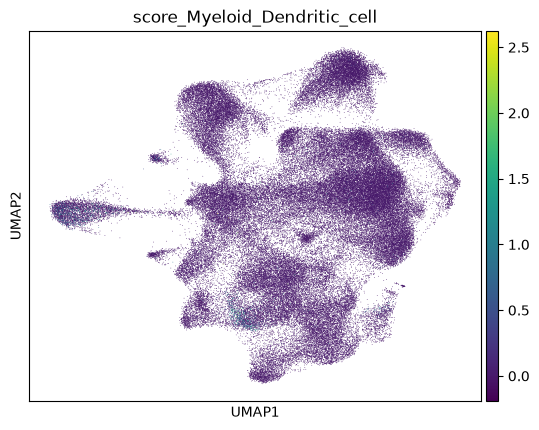

WARNING  render_shapes: Found 171793 NaN values in color data. These observations will be colored with the         
         'na_color'.                                                                                               


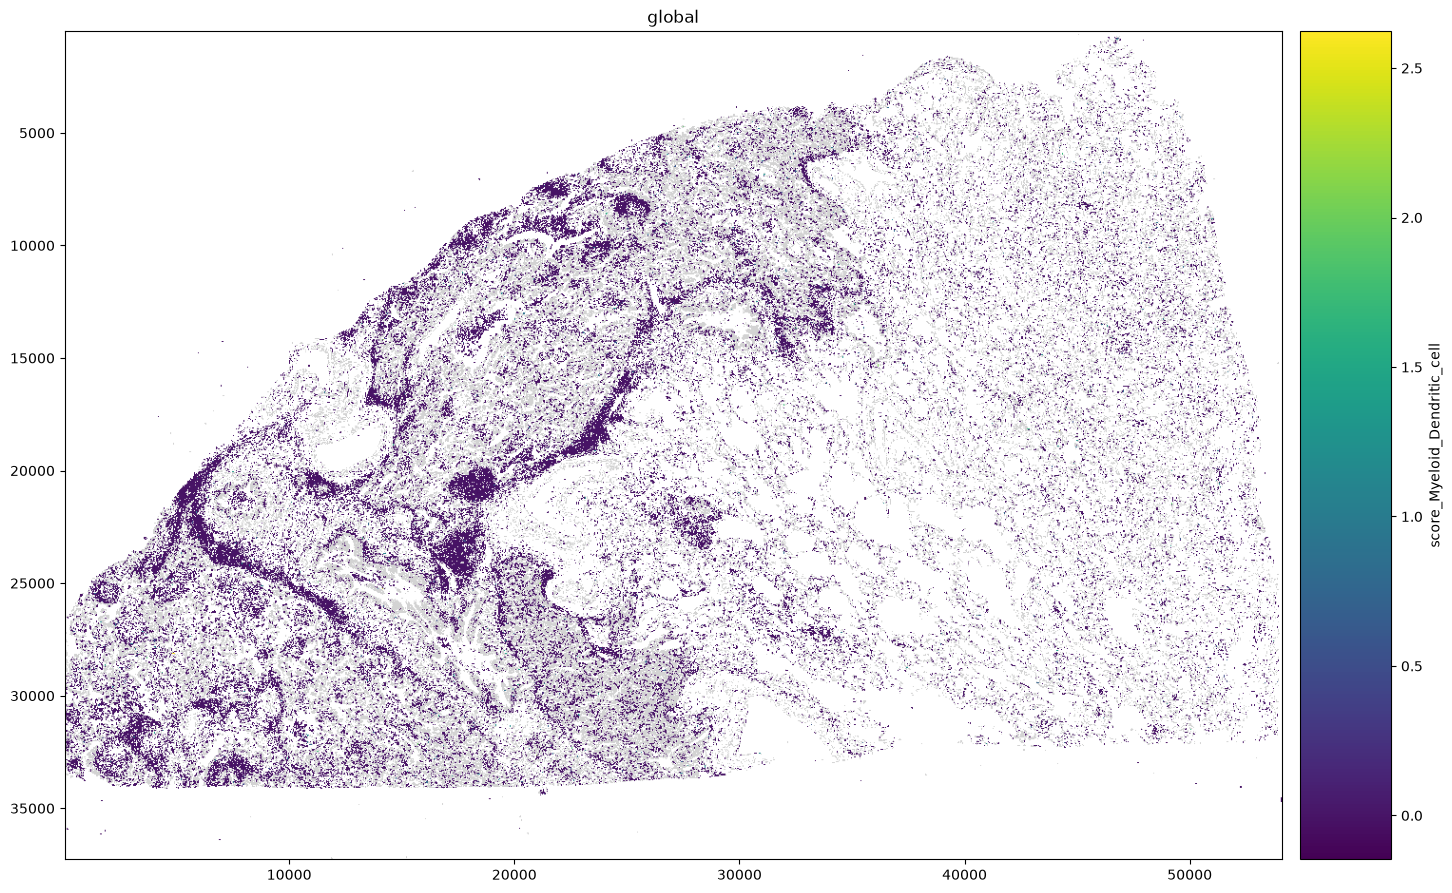

In [10]:
plot_subcluster_score(adata, sdata, 'Lymphoid_T_cell_CD8_exhausted')

### Zoom-in Visualization

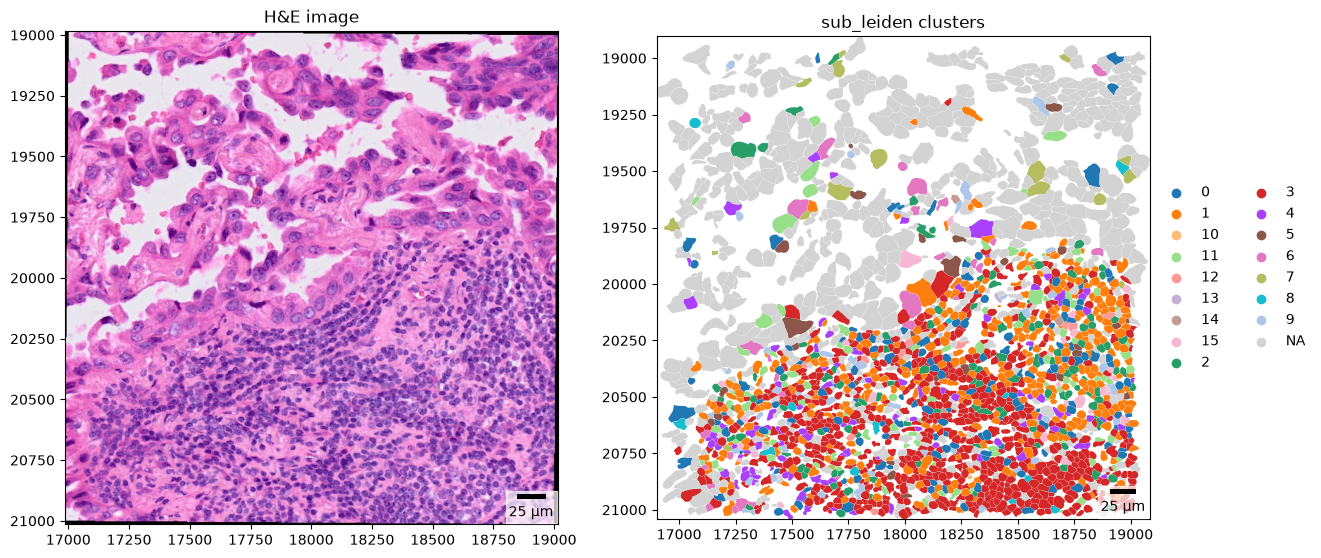

In [35]:
from spatialdata import bounding_box_query
from matplotlib_scalebar.scalebar import ScaleBar

plot_col = 'sub_leiden'
full_table = sdata.tables['table']
full_table.obs[plot_col] = adata.obs['sub_leiden'].reindex(full_table.obs.index)

# TODO: set to the region of interest (pixel coordinates)
min_x, max_x = 17_000, 19_000
min_y, max_y = 19_000, 21_000

cropped_sdata = bounding_box_query(
    sdata,
    min_coordinate=[min_x, min_y],
    max_coordinate=[max_x, max_y],
    axes=("x", "y"),
    target_coordinate_system="global",
)

axes = plt.subplots(1, 2, figsize=(14, 7))[1].flatten()

cropped_sdata.pl.render_images("he_image").pl.show(ax=axes[0], title="H&E image", coordinate_systems="global")
cropped_sdata.pl.render_shapes("cell_boundaries", color=plot_col, palette=cluster_colors).pl.show(
    ax=axes[1], title="sub_leiden clusters", coordinate_systems="global"
)

pixel_size_in_microns = 0.2125

for ax in axes:
    scalebar = ScaleBar(
        dx=pixel_size_in_microns,
        units="um",
        location="lower right",
        color="black",
        box_color="white",
        box_alpha=0.7,
        length_fraction=0.1,
    )
    ax.add_artist(scalebar)

## Layer 2 — DEG-driven manual/literature annotation

Compute DEGs per sub-cluster, pull the top 5–10 genes, then cross-check them against literature / [Human Protein Atlas](https://www.proteinatlas.org) to assign a label.

Manual calls are stored in an editable CSV (`layer2_manual_annotation.csv`) so re-running this notebook doesn't wipe out annotation work — edit the CSV directly and re-run the load cell to pick up changes.

In [36]:
sc.tl.rank_genes_groups(adata, groupby='sub_leiden', layer='lognorm', pts=True)

In [37]:
n_top_degs = 10
deg_summary = pd.concat(
    [sc.get.rank_genes_groups_df(adata, group=c).head(n_top_degs).assign(cluster=c) for c in sub_clusters],
    ignore_index=True,
)
deg_summary = deg_summary[['cluster', 'names', 'scores', 'logfoldchanges', 'pvals_adj', 'pct_nz_group', 'pct_nz_reference']]
deg_summary.to_csv(f'{annot_dir}/deg_summary.csv', index=False)
deg_summary.head(10)

,cluster,names,scores,logfoldchanges,pvals_adj,pct_nz_group,pct_nz_reference
0,0,CTLA4,90.176018,3.751877,0.000000e+00,0.633955,0.093701
1,0,FOXP3,73.339516,5.488323,0.000000e+00,0.464985,0.019090
2,0,TIGIT,63.681442,3.634121,0.000000e+00,0.432389,0.052466
3,0,CD3E,52.985756,1.390801,0.000000e+00,0.627160,0.285762
4,0,BATF,51.451351,2.975769,0.000000e+00,0.350841,0.065138
5,0,IKZF2,46.311119,3.864625,0.000000e+00,0.264455,0.025180
6,0,CCR4,41.494278,2.125190,0.000000e+00,0.311679,0.079149
7,0,RTKN2,40.272411,3.116678,0.000000e+00,0.231859,0.029902
8,0,ICOS,37.863880,2.892537,4.403017e-289,0.219074,0.036135
9,0,SIRPG,37.770687,3.149016,1.175495e-287,0.208132,0.028900


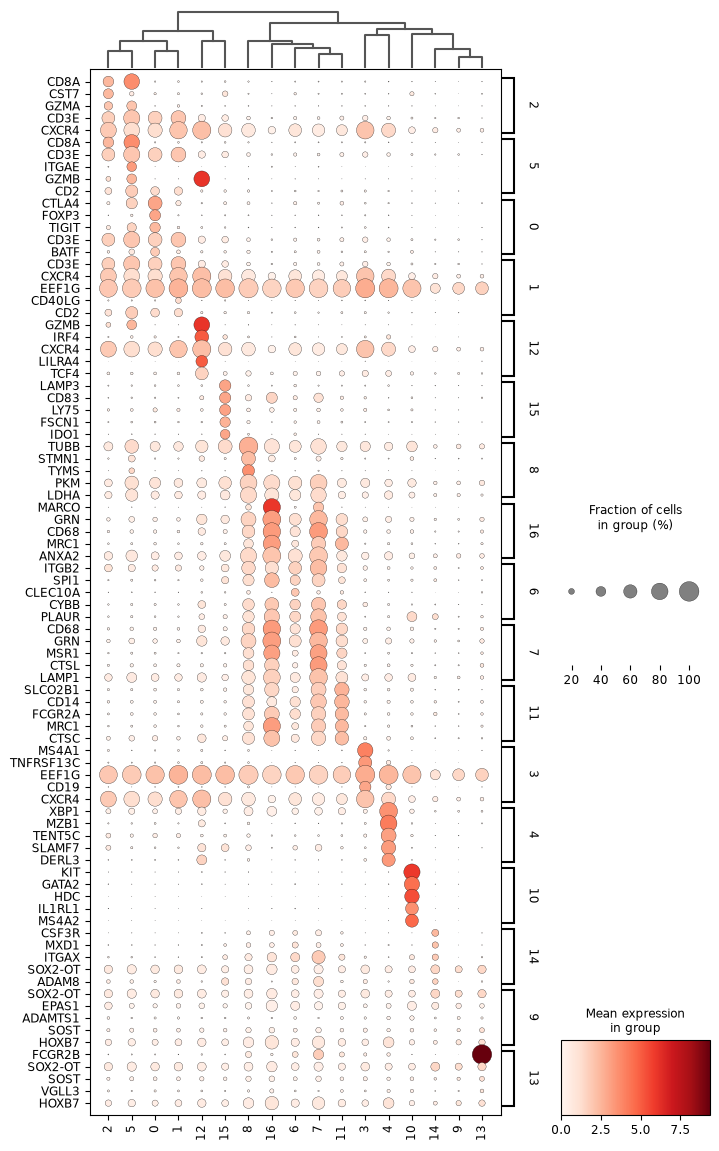

In [42]:
sc.pl.rank_genes_groups_dotplot(adata, n_genes=5, swap_axes=True, figsize=(8, max(14, 0.6 * len(sub_clusters))))

In [39]:
layer2_path = f'{annot_dir}/layer2_manual_annotation.csv'
top_degs_per_cluster = (
    deg_summary.groupby('cluster', observed=True)['names']
    .apply(lambda s: ', '.join(s))
    .reindex(sub_clusters)
)

if os.path.exists(layer2_path):
    layer2_manual_annotation = pd.read_csv(layer2_path, dtype=str).set_index('cluster')
    layer2_manual_annotation['top_degs'] = top_degs_per_cluster
    layer2_manual_annotation = layer2_manual_annotation.reset_index()
else:
    layer2_manual_annotation = pd.DataFrame({
        'cluster': sub_clusters,
        'top_degs': top_degs_per_cluster.values,
        'literature_notes': '',
        'layer2_label': '',
    })

layer2_manual_annotation.to_csv(layer2_path, index=False)
print(f'Edit {layer2_path} to fill in literature_notes / layer2_label, then re-run this cell to reload.')
layer2_manual_annotation

Edit ../../results/xenium_5k/annotation/subclustering/immune/layer2_manual_annotation.csv to fill in literature_notes / layer2_label, then re-run this cell to reload.


,cluster,top_degs,literature_notes,layer2_label
0,0,"CTLA4, FOXP3, TIGIT, CD3E, BATF, IKZF2, CCR4, ...",,
1,1,"CD3E, CXCR4, EEF1G, CD40LG, CD2, CD5, TCF7, CD...",,
2,2,"CD8A, CST7, GZMA, CD3E, CXCR4, GZMK, GZMH, ITG...",,
3,3,"MS4A1, TNFRSF13C, EEF1G, CD19, CXCR4, BANK1, C...",,
4,4,"XBP1, MZB1, TENT5C, SLAMF7, DERL3, POU2AF1, PI...",,
5,5,"CD8A, CD3E, ITGAE, GZMB, CD2, GZMA, KLRK1, CXC...",,
6,6,"ITGB2, SPI1, CLEC10A, CYBB, PLAUR, PEA15, SLC2...",,
7,7,"CD68, GRN, MSR1, CTSL, LAMP1, ANXA2, LIPA, LGM...",,
8,8,"TUBB, STMN1, TYMS, PKM, LDHA, PCNA, H2AFX, RAC...",,
9,9,"SOX2-OT, EPAS1, ADAMTS1, SOST, HOXB7, NR4A1, S...",,


KeyError: 'CD16'

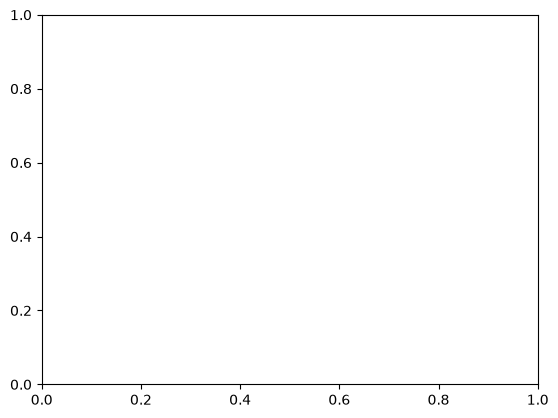

In [34]:
sc.pl.umap(adata, color='CD16', cmap='viridis', use_raw=False)

#### Cross-check top DEGs against HPA marker genes

Fisher's exact test (via `celltypegenomics`) of each sub-cluster's top DEGs against Human Protein Atlas cell-type marker gene sets, as an additional cross-check for the manual calls above.

In [44]:
from celltypegenomics import celltypefishertest

symbol_to_ensembl = adata.var['gene_ids'].to_dict()

# celltypefishertest drops any cell type with adjusted_p_value > hpa_alpha, so sub-clusters with
# subtle DEGs can come back empty at the default alpha=0.05 - relax as needed
hpa_alpha = 1.0


def hpa_fisher_test(cluster, n=n_top_degs):
    genes = deg_summary.loc[deg_summary['cluster'] == cluster, 'names'].head(n)
    ensembl_ids = [symbol_to_ensembl[g] for g in genes if g in symbol_to_ensembl]
    result = celltypefishertest(ensembl_ids, hpa_marker_genes=True, alpha=hpa_alpha)
    return result.sort_values('adjusted_p_value').assign(cluster=cluster)


hpa_annotation.groupby('cluster').head(3)

hpa_annotation = pd.concat([hpa_fisher_test(c) for c in sub_clusters], ignore_index=False)
hpa_annotation.to_csv(f'{annot_dir}/layer2_hpa_fishertest.csv')

NameError: name 'hpa_annotation' is not defined

In [ ]:
hpa_best_per_cluster = (
    hpa_annotation.reset_index(names='cell_type')
    .sort_values('adjusted_p_value')
    .groupby('cluster', sort=False)
    .first()
    .reindex(sub_clusters)[['cell_type', 'adjusted_p_value', 'odds_ratio']]
)
hpa_best_per_cluster

## Layer 3 — Functional enrichment (GO / KEGG / Reactome)

Over-representation analysis (Enrichr) on the top DEGs of each sub-cluster, to support/refine the cell type call with pathway-level evidence.

In [ ]:
gene_sets = ['GO_Biological_Process_2023', 'KEGG_2021_Human', 'Reactome_2022']
n_genes_enrichment = 50


def top_deg_genes(cluster, n=n_genes_enrichment, padj_thresh=0.05):
    df = sc.get.rank_genes_groups_df(adata, group=cluster)
    df = df[(df['pvals_adj'] < padj_thresh) & (df['logfoldchanges'] > 0)]
    return df.sort_values('scores', ascending=False)['names'].head(n).tolist()


def run_enrichment(gene_list, cluster, gene_sets=gene_sets):
    if len(gene_list) == 0:
        return pd.DataFrame()
    try:
        enr = gp.enrich_multi(gene_list=gene_list, gene_sets=gene_sets, organism='human', outdir=None)
    except AttributeError:
        # older/newer gseapy versions expose enrichr per-library instead of enrich_multi
        enr = pd.concat(
            [gp.enrichr(gene_list=gene_list, gene_sets=[gs], organism='human', outdir=None).results.assign(Gene_set=gs)
             for gs in gene_sets],
            ignore_index=True,
        )
    enr = enr.results if hasattr(enr, 'results') else enr
    enr['cluster'] = cluster
    return enr

In [ ]:
%%time
enrichment_results = {}
for c in sub_clusters:
    genes = top_deg_genes(c)
    res = run_enrichment(genes, c)
    if not res.empty:
        enrichment_results[c] = res

layer3_enrichment = pd.concat(enrichment_results.values(), ignore_index=True) if enrichment_results else pd.DataFrame()
layer3_enrichment.to_csv(f'{annot_dir}/layer3_functional_enrichment.csv', index=False)
layer3_enrichment.head(10)

In [ ]:
# Barplot of the top enriched terms for a single sub-cluster (edit cluster id as needed)
cluster_to_plot = sub_clusters[0]
top_terms = (
    layer3_enrichment[layer3_enrichment['cluster'] == cluster_to_plot]
    .sort_values('Adjusted P-value')
    .head(10)
)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_terms['Term'], -np.log10(top_terms['Adjusted P-value']))
ax.invert_yaxis()
ax.set_xlabel('-log10(adjusted p-value)')
ax.set_title(f'Top enriched terms — sub-cluster {cluster_to_plot}')
plt.tight_layout()

In [ ]:
top_enriched_terms_per_cluster = (
    layer3_enrichment.sort_values('Adjusted P-value')
    .groupby('cluster', observed=True)['Term']
    .apply(lambda s: '; '.join(s.head(3)))
    .reindex(sub_clusters)
)

## Consolidation

Merge all three layers into one summary table per sub-cluster.

In [ ]:
n_cells_per_cluster = adata.obs['sub_leiden'].value_counts().reindex(sub_clusters)

subcluster_annotation_summary = (
    layer1_annotation.set_index('cluster')
    .join(layer2_manual_annotation.set_index('cluster'))
    .assign(
        n_cells=n_cells_per_cluster,
        top_enriched_terms=top_enriched_terms_per_cluster,
    )
    .reset_index()
)
subcluster_annotation_summary.to_csv(f'{annot_dir}/subcluster_annotation_summary.csv', index=False)
subcluster_annotation_summary

Fill in `subcluster_labels` below once the layer 1-3 evidence above has been reviewed, then re-run the remaining cells to plot the final sub-type calls (in-memory only — this notebook does not persist a new zarr store).

In [ ]:
from spatialdata import bounding_box_query
from matplotlib_scalebar.scalebar import ScaleBar

# project the final sub-cell-type labels onto the full sdata table
zoom_plot_col = 'sub_cell_type'
full_table = sdata.tables['table']
full_table.obs[zoom_plot_col] = adata.obs['sub_cell_type'].reindex(full_table.obs.index)

# TODO: set to the region of interest (pixel coordinates)
min_x, max_x = 12_000, 14_000
min_y, max_y = 24_000, 25_000

cropped_sdata = bounding_box_query(
    sdata,
    min_coordinate=[min_x, min_y],
    max_coordinate=[max_x, max_y],
    axes=("x", "y"),
    target_coordinate_system="global",
)

axes = plt.subplots(1, 2, figsize=(14, 7))[1].flatten()

cropped_sdata.pl.render_images("he_image").pl.show(ax=axes[0], title="H&E image", coordinate_systems="global")
cropped_sdata.pl.render_shapes("cell_boundaries", color=zoom_plot_col).pl.show(
    ax=axes[1], title="sub_cell_type (final labels)", coordinate_systems="global"
)

pixel_size_in_microns = 0.2125

for ax in axes:
    scalebar = ScaleBar(
        dx=pixel_size_in_microns,
        units="um",
        location="lower right",
        color="black",
        box_color="white",
        box_alpha=0.7,
        length_fraction=0.1,
    )
    ax.add_artist(scalebar)

In [ ]:
# lightweight cell_id + sub-cluster export for napari (re-run after filling in subcluster_labels)
export_path = f'{annot_dir}/sub_cluster_labels.csv'
export_df = adata.obs[['cell_id', 'sub_leiden', 'sub_cell_type']].copy()
export_df.to_csv(export_path, index=False)
print(f'Saved {len(export_df)} cells -> {export_path}')

In [ ]:
# TODO: fill in final sub-type labels per sub_leiden cluster, informed by layers 1-3 above
subcluster_labels = {
    # 'Lymphoid_T_cell_CD8+': ['0'],
}

cluster_to_label = {c: label for label, cs in subcluster_labels.items() for c in cs}
adata.obs['sub_cell_type'] = adata.obs['sub_leiden'].map(cluster_to_label).astype('category')

sc.pl.umap(adata, color='sub_cell_type', legend_loc='on data', legend_fontsize=8, legend_fontoutline=2)

In [ ]:
plot_col = 'sub_cell_type'
full_table = sdata.tables['table']
full_table.obs[plot_col] = adata.obs[plot_col].reindex(full_table.obs.index)

sdata.tables['table'].obs['region'] = 'cell_boundaries'
sdata.set_table_annotates_spatialelement('table', region='cell_boundaries')
sdata.pl.render_shapes('cell_boundaries', color=plot_col).pl.show(figsize=(12.8, 9.6))